# Healthcare Provider Fraud Detection: Exploratory Data Analysis

## 1. Executive summary

This project compares healthcare providers flagged as potentially fraudulent with those that are not. The analysis is purely exploratory: it describes how flagged providers differ in their billing, operational and clinical patterns, without building predictive models.

### Key findings

Flagged providers are a minority (9.35% of providers) but submit about five times as many claims per provider and account for 57.8% of inpatient and 36.6% of outpatient claims. Typical claim amounts are nearly identical between groups (median reimbursement). Within comparable size ranges, flagged inpatient providers show higher mean reimbursement and reimbursement per beneficiary (AUC 0.62–0.76), while flagged outpatient providers depend less on a single attending physician (AUC 0.27–0.35 for the top physician's share of claims) and show no difference in amounts. Diagnoses per claim do not differ in either claim type. These are moderate, descriptive associations, not evidence of fraudulent intent, and measures tied to provider size (number of physicians, diversity indices) may still partly reflect volume rather than billing behavior.

### Objective

Identify financial, operational and clinical patterns that distinguish potentially fraudulent providers from those that are not.

### Scope and approach

- **The unit of analysis is the provider**. The fraud label is assigned to providers, not to individual claims, so findings describe how flagged providers look.
- **Inpatient and outpatient claims are analyzed separately**, since their reimbursement scales and available variables are not comparable.
- **Provider size** is taken into account because flagged providers tend to be larger: comparisons are also made within provider-size ranges to separate volume effects from differences in billing behavior.

### Business questions

1. **Financial patterns:** How do reimbursed amounts and reimbursement per beneficiary differ between flagged and non-flagged providers? 
2. **Operational patterns:** Is there evidence of over-utilization, such as longer hospital stays or more claims per beneficiary?
3. **Patient and diagnostic complexity:** Do flagged providers treat more complex patients (more diagnoses per claim), or are some diagnosis codes over-represented in their claims?
4. **Concentration and variety:** Is billing more concentrated or more diverse across diagnoses and attending physicians, once provider size is taken into account?

### Data

Dataset: [Healthcare Provider Fraud Detection Analysis](https://www.kaggle.com/datasets/rohitrox/healthcare-provider-fraud-detection-analysis) (Kaggle), downloaded on November 5, 2026. It includes inpatient claims, outpatient claims, beneficiary demographics and a provider-level fraud label.

### Limitations

- `Provider_flag` is a provider-level label that indicates potential fraud, not confirmed fraud.
- Differences are descriptive associations, not evidence of causality or fraudulent intent.
- Medians use only providers with at least as many claims as the 25th percentile of their claim type; the feature comparisons by size range use all providers with at least 10 per class in each range.
- Size control is approximate (three ranges), and AUC values are reported without confidence intervals or significance tests.
- Beneficiary annual reimbursement columns contain negative values (minimum −8,000 inpatient, −70 outpatient), which suggest adjustments; these columns are not used in the provider-level analysis.

In [1]:
# Import required libraries
#file managment
from pathlib import Path
#data analysis
import pandas as pd
import numpy as np
#visualization
import matplotlib.pyplot as plt
import seaborn as sns 
#data download
import kagglehub
#statistics
import scipy.stats as stats
#project helpers
import utils as ut

## 2. Data quality analysis

- Check size, duplicated rows, missing values and key integrity in each source before merging them.
- Only the labeled (training) data are used, since the test files do not include labels.

In [2]:
# Download and load dataset from kagglehub
kagg_path=Path(kagglehub.dataset_download(
    "rohitrox/healthcare-provider-fraud-detection-analysis"))
# Use file patterns to identify csv files 
filename_patterns={
    "Outpatient": "Train_Outpatientdata*.csv",
    "Inpatient": "Train_Inpatientdata*.csv",
    "Beneficiary": "Train_Beneficiarydata*.csv",
    "Provider": "Train-*.csv",
}
# Load csv files in a dictionary
subsets={name: ut.load_subset(
    pattern, kagg_path) for name, pattern in filename_patterns.items()}

In [3]:
data_quality_summary=pd.DataFrame({
    name:{
        "Rows":subset.shape[0],
        "Columns":subset.shape[1],
        "Duplicated rows":subset.duplicated().sum(),
        "Columns with nulls":(subset.isna().sum() > 0).sum(),
        "% of null cells":round(subset.isna().mean().mean() * 100, 2)
    }
    for name, subset in subsets.items()
}).T 

data_quality_summary

,Rows,Columns,Duplicated rows,Columns with nulls,% of null cells
Outpatient,517737.0,27.0,0.0,20.0,57.90
Inpatient,40474.0,30.0,0.0,19.0,28.33
Beneficiary,138556.0,25.0,0.0,1.0,3.96
Provider,5410.0,2.0,0.0,0.0,0.00


In [4]:
for name, subset in subsets.items():
    nulls=subset.isna().sum()
    nulls=nulls[nulls > 0].sort_values(ascending=False)
    if not nulls.empty:
        print(f"\n{name}: Columns with null values")
        print(pd.
            DataFrame({"nulls": nulls, 
                       "%": (nulls / len(subset) * 100)
                .round(2)}))


Outpatient: Columns with null values
                        nulls       %
ClmProcedureCode_6     517737  100.00
ClmProcedureCode_5     517737  100.00
ClmProcedureCode_4     517735  100.00
ClmProcedureCode_3     517733  100.00
ClmProcedureCode_2     517701   99.99
ClmProcedureCode_1     517575   99.97
ClmDiagnosisCode_10    516654   99.79
ClmDiagnosisCode_9     502899   97.13
ClmDiagnosisCode_8     494825   95.57
ClmDiagnosisCode_7     484776   93.63
ClmDiagnosisCode_6     468981   90.58
ClmDiagnosisCode_5     443393   85.64
OperatingPhysician     427120   82.50
ClmAdmitDiagnosisCode  412312   79.64
ClmDiagnosisCode_4     392141   75.74
OtherPhysician         322691   62.33
ClmDiagnosisCode_3     314480   60.74
ClmDiagnosisCode_2     195380   37.74
ClmDiagnosisCode_1      10453    2.02
AttendingPhysician       1396    0.27

Inpatient: Columns with null values
                     nulls       %
ClmProcedureCode_6   40474  100.00
ClmProcedureCode_5   40465   99.98
ClmProcedureCode_4   4

No duplicated rows were found in any of the four sources. Missing values are concentrated in columns where they are expected:

- **Procedure and secondary diagnosis codes** (`ClmProcedureCode_*`, `ClmDiagnosisCode_2` to `_10`): a claim lists only the procedures and diagnoses that apply, so higher-numbered positions are empty for most claims.
- 
- **Structural fields:** admission and discharge fields exist only for inpatient claims, and some beneficiary fields (e.g., date of death) are filled only when applicable.

These missing values reflect how the data is recorded rather than data loss, so they are not imputed.

### Data subsets

The dataset consists of three claim-related sources and a provider-level label file:

1. **Inpatient**: one row per claim for patients admitted to a hospital.
2. **Outpatient**: one row per claim for patients receiving care without admission.
3. **Beneficiary**: one row per insured individual, with demographics, chronic conditions and annual reimbursement and deductible amounts.
4. **Provider labels**: one row per provider, indicating whether it is flagged as potentially fraudulent (`Provider_flag`). The label applies to the provider, not to individual claims.

Claims are linked to beneficiaries through `BeneID` and to the fraud label through `Provider`.

### Key variables

- **Identifiers and label**
    - **`ClaimID`**: unique identifier of the claim.
    - **`BeneID`**: identifier of the insured individual.
    - **`Provider`**: identifier of the clinic or hospital submitting the claim.
    - **`Provider_flag`**: provider-level flag (`Flagged` / `Non-flagged`).

- **Financial metrics**
    - **`InscClaimAmtReimbursed`**: amount reimbursed by the insurer for the claim.
    - **`IPAnnualReimbursementAmt`, `OPAnnualReimbursementAmt`**: annual inpatient and outpatient amounts per beneficiary.

- **Temporal variables**
    - **`ClaimStartDt` and `ClaimEndDt`**: start and end dates of the claim.
    - **`AdmissionDt` and `DischargeDt`**: admission and discharge dates (for inpatient claims only).

- **Clinical and administrative details**
    - **`ClmAdmitDiagnosisCode`**: diagnosis code recorded at admission.
    - **`ClmDiagnosisCode_1` to `_10`**: diagnosis codes listed on the claim. The first is the primary diagnosis, and the rest are secondary.
    - **`ChronicCond_*`**: indicators of chronic conditions of the beneficiary.
    - **`AttendingPhysician`**: identifier of the physician mainly responsible for the patient's care.
    - **`OperatingPhysician`**: identifier of the physician who performed a procedure, when applicable.

## 3. Data integration

Inpatient and outpatient claims are stacked into a single claims table (with a `Type` flag), then merged with beneficiary data (`BeneID`) and the provider fraud label (`Provider`). Left joins are used so that no claim is dropped, and each join is validated to be many-to-one so rows are never duplicated. The result is `master_df`, with one row per claim.

In [5]:
# Merge Inpatient and Outpatient claim data
#flag claim type
claims_df=pd.concat([
    subsets['Inpatient'].assign(Type="Inpatient"),
    subsets['Outpatient'].assign(Type="Outpatient"),
],ignore_index=True)

# Merge claim data with Beneficiary and Provider data
master_df = (claims_df
    .merge(subsets['Beneficiary'], 
           on="BeneID", 
           how="left", 
           validate="many_to_one")
    .merge(subsets['Provider'], 
           on="Provider", 
           how="left", 
           validate="many_to_one"))
assert len(master_df) == len(claims_df)

## 4. Feature engineering

Variables derived from dates and amounts:
-  **`n_chronic_cond`**: Total count of chronic conditions recorded for the beneficiary.
-  **`n_claim_dx`**: Total count of diagnosis codes billed under a single claim.
- **`days_in_hospital`**: days between admission and discharge (for inpatient claims only).
- **`daily_cost`**: reimbursed amount divided by `days_in_hospital`.
- **`age`**: beneficiary age in years at the claim start date.

In [6]:
#date columns
date_cols=['AdmissionDt',
           'DischargeDt',
           'ClaimStartDt',
           'ClaimEndDt',
           'DOB']
master_df[date_cols]=(master_df[date_cols]
    .apply(pd.to_datetime, errors="coerce"))

#hospital stay
days_in_hospital=((master_df['DischargeDt'] - 
                  master_df['AdmissionDt'])
    .dt.days)

chronic_cols = master_df.filter(regex="^ChronicCond_").columns
dx_cols = master_df.filter(regex="^ClmDiagnosisCode_").columns

#master dataframe
master_df=master_df.assign(
    days_in_hospital=days_in_hospital,
    daily_cost=(master_df['InscClaimAmtReimbursed'] / 
                          days_in_hospital
                              .where(days_in_hospital > 0)),
    age=(master_df['ClaimStartDt'] - 
         master_df['DOB'])
        .dt.days / 365.25,
    n_chronic_cond=(master_df[chronic_cols] == 1)
        .sum(axis=1),
    n_claim_dx=master_df[dx_cols].notna()
        .sum(axis=1),
)
#change label names
master_df.rename(columns={'PotentialFraud': 'Provider_flag'}, inplace=True)
master_df['Provider_flag']=master_df[
    'Provider_flag'].replace({
        'Yes': 'Flagged', 
        'No': 'Non-flagged'})

## 5. Class imbalance

Before comparing flagged and non-flagged providers, we need to know how large each group is and at which level (claim, beneficiary, provider) the data can be compared. This determines which summary statistics and statistical tests are appropriate for analysis.

In [7]:
#number of total claims and providers for 
#inpatient and outpatient classes
imbalance_df=(
    master_df
        .groupby(['Type','Provider_flag'])
        .agg(
            n_claim=('ClaimID','nunique'),
            n_prov=('Provider','nunique'))
        .unstack("Provider_flag")
    )

imbalance_df.columns=[f"{m}_{f}" for m, f in imbalance_df.columns]
#calculate percentages
imbalance_df=(imbalance_df.assign(
    perc_flagged_provs=lambda df: df["n_prov_Flagged"]
    /(df["n_prov_Flagged"]+df["n_prov_Non-flagged"])*100,
    perc_flagged_claims=lambda df: df["n_claim_Flagged"]
    /(df["n_claim_Flagged"]+df["n_claim_Non-flagged"])*100
    ).round(2))
#change column names
imbalance_df.rename(columns={
    "n_prov_Non-flagged": "Non-flagged providers", 
    "n_prov_Flagged": "Flagged providers",
    "n_claim_Non-flagged": "Claims from non-flagged providers",
    "n_claim_Flagged": "Claims from flagged providers",
    "perc_flagged_provs": "Flagged providers (%)",
    "perc_flagged_claims": "Claims from flagged providers (%)"
    }
                    )

,Claims from flagged providers,Claims from non-flagged providers,Flagged providers,Non-flagged providers,Flagged providers (%),Claims from flagged providers (%)
Type,,,,,,
Inpatient,23402,17072,440,1652,21.03,57.82
Outpatient,189394,328343,462,4550,9.22,36.58


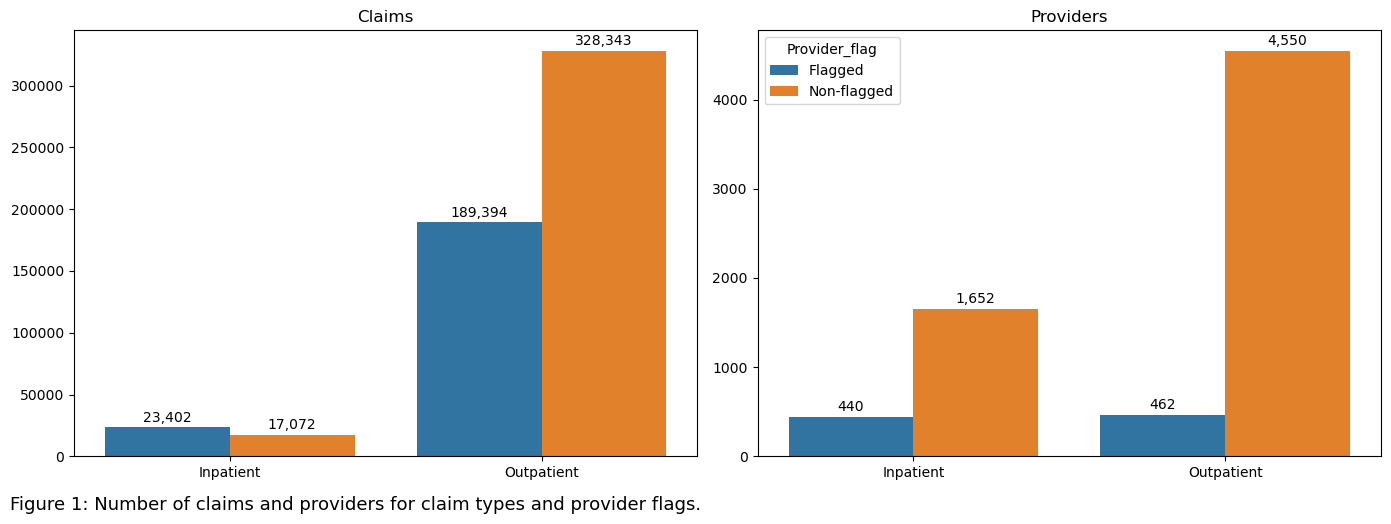

In [8]:
class_counts = (
    master_df
    .groupby(["Type", "Provider_flag"], as_index=False)
    .agg(n_claim=("ClaimID", "nunique"), 
         n_prov=("Provider", "nunique"))
)
#labels for plots
lbl=ut.plot_lbls
vars_to_plot={"n_claim": "Claims", 
             "n_prov": "Providers"}
#set figure size
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
#create plots
for i, (ax, (col, title)) in enumerate(zip(axes, vars_to_plot.items())):
    sns.barplot(data=class_counts, 
                x="Type", 
                y=col, 
                hue="Provider_flag",
                ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt="{:,.0f}", padding=2)
    ax.set(title=title, xlabel="", ylabel="")
    if i < len(axes) - 1:
        ax.get_legend().remove()
fig.tight_layout()
fig.text(0.01, -0.03,
         "Figure 1: Number of claims and providers for claim types and provider flags.",
         fontsize=13, 
         ha="left")
plt.show()

Because the analysis is done at the provider level, claim volume is handled through medians and comparisons within provider-size ranges, so the larger share of claims from flagged providers does not drive the results.

In [9]:
#variable skewness and kurtosis
claim_cols={
    'Outpatient':['InscClaimAmtReimbursed',
                  'n_claim_dx'],
    'Inpatient':['daily_cost',
                 'days_in_hospital',
                 'InscClaimAmtReimbursed',
                 'n_claim_dx']
}
claim_stats=(pd.concat([
    master_df.loc[master_df["Type"] == claim_type, col_name]
        .agg(['skew', 'kurt','nunique'])
        .T
        .rename_axis("variable")
        .reset_index()
        .assign(Type=claim_type)
    for claim_type, col_name in claim_cols.items()
],
                 ignore_index=True
                 )
      )
claim_stats['shape']=ut.distribution_shape(claim_stats)
claim_stats.round(2)

,variable,skew,kurt,nunique,Type,shape
0,InscClaimAmtReimbursed,34.61,4172.18,342.0,Outpatient,skewed
1,n_claim_dx,1.49,1.95,11.0,Outpatient,skewed
2,daily_cost,6.16,74.28,1052.0,Inpatient,skewed
3,days_in_hospital,2.61,8.51,36.0,Inpatient,skewed
4,InscClaimAmtReimbursed,3.23,15.71,146.0,Inpatient,skewed
5,n_claim_dx,-1.66,2.12,10.0,Inpatient,skewed


In [10]:
#variable skewness and kurtosis
bene_df=subsets["Beneficiary"].copy()
chronic_cols = (bene_df
    .filter(regex="^ChronicCond_")
    .columns)
bene_df['n_chronic_cond']=((bene_df[
    chronic_cols] == 1)
    .sum(axis=1))
bene_cols=['OPAnnualReimbursementAmt',
           'IPAnnualReimbursementAmt',
           'n_chronic_cond']

bene_stats=(bene_df[bene_cols]
    .agg(['skew', 'kurt','nunique'])
    .T
    .rename_axis("variable")
    .reset_index())

bene_stats['shape']=ut.distribution_shape(bene_stats)
bene_stats.round(2)

,variable,skew,kurt,nunique,shape
0,OPAnnualReimbursementAmt,8.61,159.62,2078.0,skewed
1,IPAnnualReimbursementAmt,4.64,31.03,3004.0,skewed
2,n_chronic_cond,0.28,-0.66,12.0,approx. symmetric


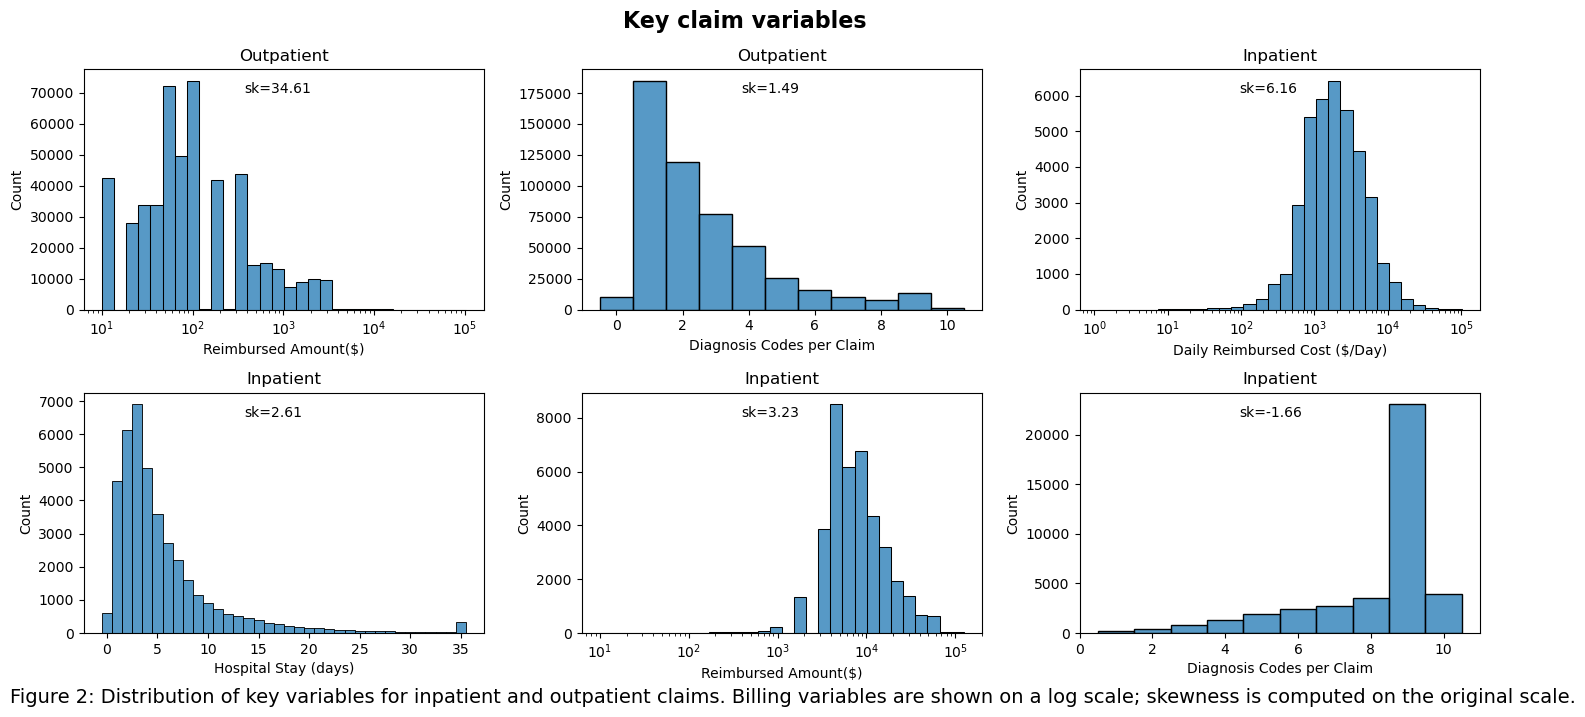

In [11]:
n_vars=len(claim_stats)
n_cols=3
n_rows=int(n_vars/n_cols)
discrete_vars=["days_in_hospital", 
               "n_claim_dx"]
log_vars = ["InscClaimAmtReimbursed", "daily_cost"]

fig, axes=plt.subplots(n_rows,n_cols,figsize=(15,7))

for i in np.arange(n_vars):
    var_name, var_skew, c_type=(claim_stats[[
        "variable",
        "skew",
        "Type"]]
        .iloc[i])
    r=i//n_cols
    if i<n_cols: 
        c=i
    else:
        c=i-n_cols
    ax=axes[r,c]
    claim_type_df=master_df[master_df["Type"]==c_type]
    dv = var_name in discrete_vars
    sns.histplot(data=claim_type_df, x=var_name, 
                 ax=ax, discrete=dv,
                 bins="auto" if dv else 30, 
                 log_scale=var_name in log_vars)
    ax.text(0.4,0.9,f"sk={var_skew:.2f}",
            transform=ax.transAxes,
            fontsize=10)
    ax.set_xlabel(lbl[var_name])
    ax.set_title(c_type, 
                 loc="center")
fig.suptitle("Key claim variables",weight="bold",size=16)
fig.tight_layout()
fig.text(0.01, -0.01,
         "Figure 2: Distribution of key variables for inpatient and outpatient claims. "
             "Billing variables are shown on a log scale; skewness is computed on the original scale.",
         fontsize=14, ha="left")
plt.show()

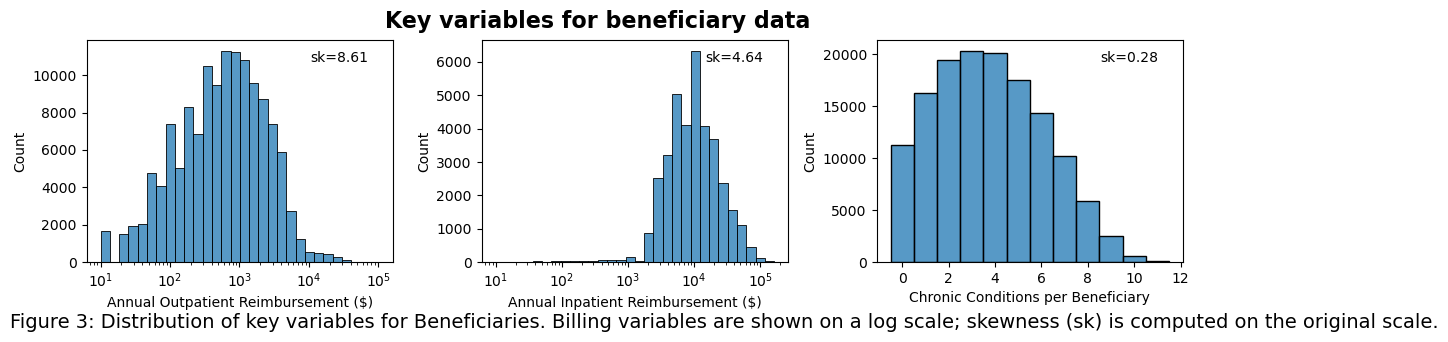

In [12]:
fig, axes=plt.subplots(1,3,figsize=(12,3))
discrete_vars=['n_chronic_cond']
log_vars=['OPAnnualReimbursementAmt','IPAnnualReimbursementAmt']

for i in np.arange(len(bene_stats)):
    var_name, var_skew=(bene_stats[[
        "variable",
        "skew"]]
        .iloc[i])
    ax=axes[i]
    dv=var_name in discrete_vars
    sns.histplot(data=bene_df, x=var_name,
                 discrete=dv,
                 bins="auto" if dv else 30,ax=ax,
                log_scale=var_name in log_vars)
    ax.text(0.73,0.9,f"sk={var_skew:.2f}",
            transform=ax.transAxes,
            fontsize=10)
    ax.set_xlabel(lbl[var_name])

fig.tight_layout()
fig.suptitle("Key variables for beneficiary data",weight="bold",size=16,y=1.05)
fig.text(0.01, -0.01,
         "Figure 3: Distribution of key variables for Beneficiaries. "
             "Billing variables are shown on a log scale; skewness (sk) is computed on the original scale.",
         fontsize=14, ha="left")
plt.show()

Almost all key variables have a non symmetric distribution. The only variable  with a symmetric distribution is the number of chronic condition per beneficiary.

### Results

Flagged providers are a minority of providers but account for a disproportionate share of claims:

- **Inpatient:** 440 of 2,092 providers (21.0%) are flagged, yet they submit 57.8% of all inpatient claims (23,402 of 40,474).
- **Outpatient:** 462 of 5,012 providers (9.2%) are flagged, and they submit 36.6% of all outpatient claims (189,394 of 517,737).

On average, a flagged provider submits roughly five times as many claims as a non-flagged one (about 53 vs. 10 inpatient claims, and 410 vs. 72 outpatient claims per provider). Flagged providers are therefore considerably larger, which has two implications for the rest of the analysis:

1. **The unit of analysis is the provider.** Comparing individual claims would give most of the weight to flagged providers and would mix provider size with billing behavior.
2. **Provider size must be taken into account.** Many billing metrics grow with volume, so comparisons are summarized with robust statistics (medians) and effect sizes, and are also repeated within provider-size ranges.

*Note: providers can appear in both claim types, so provider counts are not additive across Inpatient and Outpatient. Percentages are computed over providers with at least one claim of the given type.*

## 6. Provider-level aggregation

The fraud label is assigned to providers, not to claims, so claims are aggregated per provider and claim type. For each provider and claim type, the **median** of each metric is computed together with the number of claims and of unique beneficiaries. Inpatient and outpatient claims are summarized separately, using only the variables available for each type.

**Minimum number of claims.** Medians based on very few claims are unstable. To avoid this, providers are kept only if they have at least as many claims as the 25th percentile of claims per provider, computed separately for each claim type. This corresponds to a minimum of 3 claims for inpatient and 11 for outpatient providers. Because flagged providers tend to be larger, the filter removes proportionally fewer flagged than non-flagged providers.

In [13]:
summ_cols={
    "Inpatient": ['days_in_hospital',
                  'daily_cost',
                  'InscClaimAmtReimbursed'
                 ],
    "Outpatient": ['InscClaimAmtReimbursed'],
}

claims_by_type={df_type: df for df_type, df in master_df.groupby('Type')}
prov_by_type_summ={}

for claim_type, col_names in summ_cols.items():
    agg_dict={
        **{f"median_{col}":(col, 'median') for col in col_names},
        'n_bene': ('BeneID','nunique'),
        'n_claims': ('ClaimID', 'nunique')
    }
    prov_by_type_summ[claim_type]=(claims_by_type[claim_type]
                                     .groupby(["Provider", 
                                               "Provider_flag"], 
                                              as_index=False)
        .agg(**agg_dict))

prov_by_type_summ_filtered={
    df_type: df[df['n_claims'] >= (np.quantile(df['n_claims'], 0.25))] for 
    df_type, df in prov_by_type_summ.items()}

### Financial patterns
#### Reimbursed amounts

Figure 4 compares the median reimbursed amount per provider. In both claim types the centers of the two distributions practically coincide (around \\$7,000 per inpatient claim and below \\$100 per outpatient claim), so the typical claim of a flagged provider is not more expensive than that of a non-flagged one. The groups differ in spread: non-flagged providers have a longer right tail and more mass at lower values, while flagged providers concentrate in a narrower range.

This tighter distribution should be read with caution. Flagged providers submit about five times more claims, and a median computed from more claims varies less by chance alone. 

The size-stratified comparison and the within-provider variability (coefficient of variation) in later sections help separate this sampling effect from real differences in billing behavior.

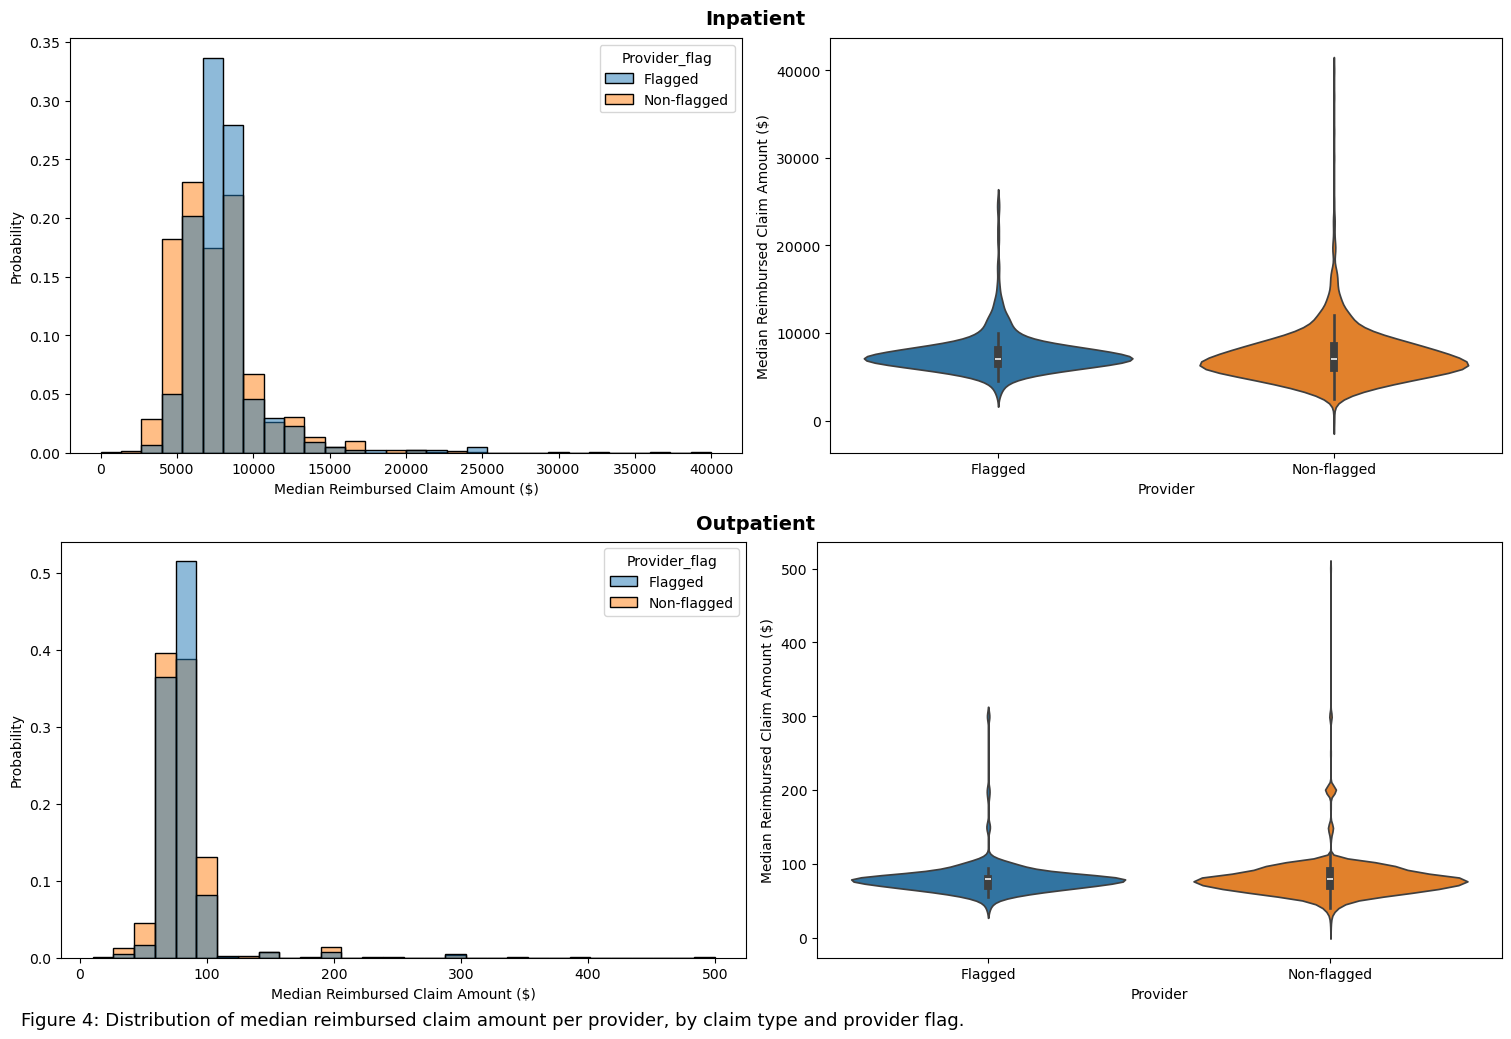

In [14]:
var_to_plot='median_InscClaimAmtReimbursed'
fig=plt.figure(figsize=(15, 10), layout="constrained")
subfigs=fig.subfigures(2, 1)

for subfig,(claim_type, df) in zip(subfigs, prov_by_type_summ_filtered.items()):
    ax_hist,ax_violin=subfig.subplots(1,2)
    subfig.suptitle(claim_type, fontsize=14,fontweight="bold")
    ut.plot_hist_violin(
        data=df, 
        ax_hist=ax_hist, 
        ax_violin=ax_violin,
        x=var_to_plot,
        xlabel_hist=lbl[var_to_plot],
        xlabel_violin="Provider",
        ylabel_violin=lbl[var_to_plot]
    )
fig.text(0.01, -0.02,
         "Figure 4: Distribution of median reimbursed claim amount per provider, "
         "by claim type and provider flag.",
         fontsize=13, ha="left")
plt.show()

### Operational patterns

Figure 5 shows a similar pattern for operational metrics. The median hospital stay is about four days in both groups, with flagged providers tightly concentrated around that value, while non-flagged providers include more providers with short stays (1–2 days) and a long tail of median stays above 10 days. Median daily reimbursed cost is also centered at roughly \$1,800–2,000 per day in both groups, with non-flagged providers spreading toward both lower and higher values.

There is therefore no evidence that flagged providers have longer stays or higher daily costs at the median; if anything, their values are more uniform, which, as in Figure 4, may partly reflect provider size. Possible over-utilization is better assessed through claim volume per beneficiary, examined in the next sections.

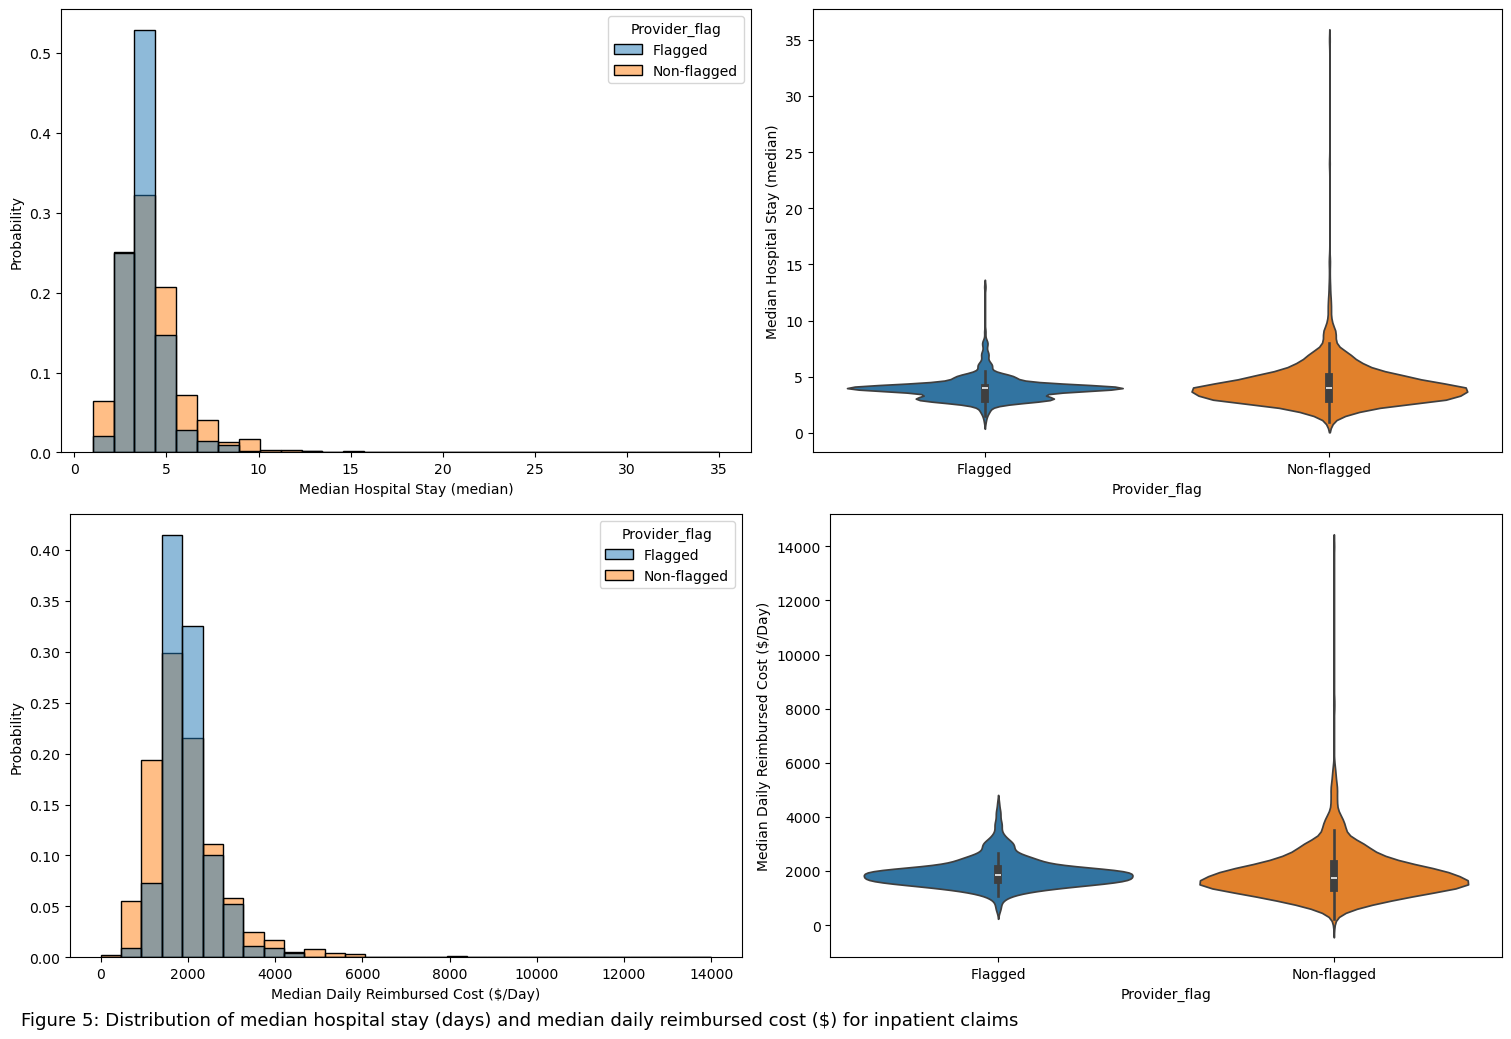

In [15]:
vars_to_plot=['median_days_in_hospital','median_daily_cost']
inp_df=prov_by_type_summ_filtered['Inpatient']

fig=plt.figure(figsize=(15, 10), layout="constrained")
subfigs=fig.subfigures(2,1)

for subfig,var in zip(subfigs, vars_to_plot):
    ax_hist,ax_violin=subfig.subplots(1,2)
    #subfig.title(lbl[var], fontsize=14,fontweight="bold")
    ut.plot_hist_violin(
        data=inp_df, 
        ax_hist=ax_hist, 
        ax_violin=ax_violin,
        x=var,
        xlabel_hist=lbl[var],
        ylabel_violin=lbl[var]
    )
    
    
fig.text(0.01, -0.02,
         "Figure 5: Distribution of median hospital stay (days) "
         "and median daily reimbursed cost ($) for inpatient claims",
         fontsize=13, ha="left")
plt.show()

### Diagnostic complexity

To check whether some diagnoses are over-represented in flagged providers' claims, claims are grouped by primary diagnosis (`ClmDiagnosisCode_1`) and claim type. For each code, *lift* is the share of flagged claims carrying the code divided by the share of non-flagged claims carrying it (lift > 1: over-represented among flagged providers). A 0.5 continuity correction is applied, and codes are ranked by the **lower bound of the 95% confidence interval** of the lift, so a code is listed only when its over-representation is distinguishable from 1 and not driven by a handful of claims.

In [16]:
# Group 'master_df' by the first diagnosis code, count 
#number of providers and estimate median for
#the daily reimbursed amount and total reimbursed amount
dxcodes_df_summ=(
    master_df
    .groupby(["ClmDiagnosisCode_1", "Type", "Provider_flag"])
    .agg(
        median_daily_amount=("daily_cost", "median"),
        median_reimb_amount=("InscClaimAmtReimbursed","median"),
        n_claims=("ClaimID", "nunique"),
        n_providers=('Provider',"nunique")
    )
    .unstack("Provider_flag")
)
#flat column names
dxcodes_df_summ.columns=[f"{m}_{f}" 
                           for m, f in dxcodes_df_summ.columns]
#replace NA values with 0 in number of claims and number of
#providers columns
count_cols=[c for c in dxcodes_df_summ 
            if c.startswith(("n_claims", "n_providers"))]
dxcodes_df_summ[count_cols]=dxcodes_df_summ[
    count_cols].fillna(0).astype(int)

# Total number of claims per diagnosis code and add 
#totals to 'dxcodes_df_summ'
total_dxcodes=(master_df
    .groupby(['Type','Provider_flag'])['ClaimID']
    .nunique()
    .unstack()
                  )
dxcodes_df_summ=dxcodes_df_summ.reset_index()
dxcodes_df_summ['tot_flagged']=dxcodes_df_summ['Type'].map(total_dxcodes['Flagged'])
dxcodes_df_summ['tot_nonflagged']=dxcodes_df_summ['Type'].map(total_dxcodes['Non-flagged'])

# Estimate risk ratio of diagnosis codes ('lift')
#smooth lift values
n_claims_y_smooth=dxcodes_df_summ["n_claims_Flagged"] + 0.5
n_claims_n_smooth=dxcodes_df_summ["n_claims_Non-flagged"] + 0.5 
lift=(n_claims_y_smooth/
      dxcodes_df_summ["tot_flagged"])/(
    n_claims_n_smooth/
    dxcodes_df_summ["tot_nonflagged"])
# Estimate lower CI of lift values 
#standard error
se=np.sqrt(1/n_claims_y_smooth - 
           1/dxcodes_df_summ["tot_flagged"] + 
           1/n_claims_n_smooth -   
           1/dxcodes_df_summ["tot_nonflagged"])
#lower CI
dxcodes_df_summ["lift_lower"]=np.exp(np.log(lift) - 1.96 * se)
top=(dxcodes_df_summ[dxcodes_df_summ["lift_lower"] > 1][[
    'ClmDiagnosisCode_1',"Type", "lift_lower"]]
    .sort_values(["Type", "lift_lower"], ascending=[True, False]))
top.groupby("Type").head(10)

,ClmDiagnosisCode_1,Type,lift_lower
4986,43401,Inpatient,1.117801
4755,41402,Inpatient,1.029437
9606,81209,Inpatient,1.021878
912,1530,Inpatient,1.020313
11510,99833,Outpatient,1.654322
7162,69018,Outpatient,1.635645
3836,36543,Outpatient,1.578864
3211,33181,Outpatient,1.489854
1794,2239,Outpatient,1.445318
3657,36119,Outpatient,1.438846


**Results.** In inpatient claims only four codes have a lower bound above 1, and barely so (1.02–1.12), so no inpatient diagnosis stands out. In outpatient claims the top ten codes have lower bounds between 1.31 and 1.65, making them the most interesting candidates for review in future analyses.

**Caveats.**
- Thousands of codes are tested without multiple-comparison correction; at a 95% level, some codes will exceed 1 by chance alone, which is consistent with the weak inpatient list.
- Lift counts claims, not providers. Claims from the same provider are not independent, so one large flagged provider can drive a code. Requiring a minimum number of distinct flagged providers (`n_providers`) would make the ranking more robust.
- Over-representation may reflect the specialty mix of flagged providers rather than abusive billing.

### Financial features
#### Provider-level volume, billing and concentration features

For each provider and claim type we compute: number of claims and beneficiaries; coefficient of variation (standard deviation/mean); reimbursement and claims per beneficiary; mean number of diagnoses per claim; number of distinct attending physicians; share of claims handled by the top physician and top diagnosis; and Shannon entropy of physicians and diagnoses.

Since flagged providers are larger, each feature is compared **within three provider-size ranges** (by total claims) using the AUC: the probability that a randomly chosen flagged provider has a higher value than a non-flagged one of similar size. AUC = 0.5 means no difference, > 0.5 higher in flagged providers, < 0.5 lower. Size ranges are numbered 0 (smallest) to 2 (largest); ranges with fewer than 10 providers in either group are omitted.

In [17]:
dx_cols = master_df.filter(regex="^ClmDiagnosisCode_").columns
    
findata_summ = (
    master_df
    .assign(n_claim_dx=lambda df: df[dx_cols].count(axis=1))
    .groupby(['Provider', 'Type','Provider_flag'])
    .agg(
        mean_n_dx=('n_claim_dx', 'mean'),
        total_claims=('ClaimID', 'count'),
        n_bene=('BeneID','nunique'),
        reimb_amount_sd=('InscClaimAmtReimbursed','std'),
        reimb_amount_mean=('InscClaimAmtReimbursed','mean'),
        reimb_amount_tot=('InscClaimAmtReimbursed','sum'),
        n_attending=("AttendingPhysician", "nunique"),
        top_attphy_share=("AttendingPhysician", ut.topshare),
        top_dx_share=("ClmDiagnosisCode_1", ut.topshare),
        attphy_entropy=("AttendingPhysician",ut.shanentropy),
        dx_entropy=('ClmDiagnosisCode_1', ut.shanentropy)
    )
        .assign(cv_reimb_amount=lambda df: df['reimb_amount_sd']/df['reimb_amount_mean'],
                reimb_per_bene=lambda df: df['reimb_amount_tot']/df['n_bene'],
                n_claims_per_bene=lambda df: df['total_claims']/df['n_bene']
               ).reset_index()
)

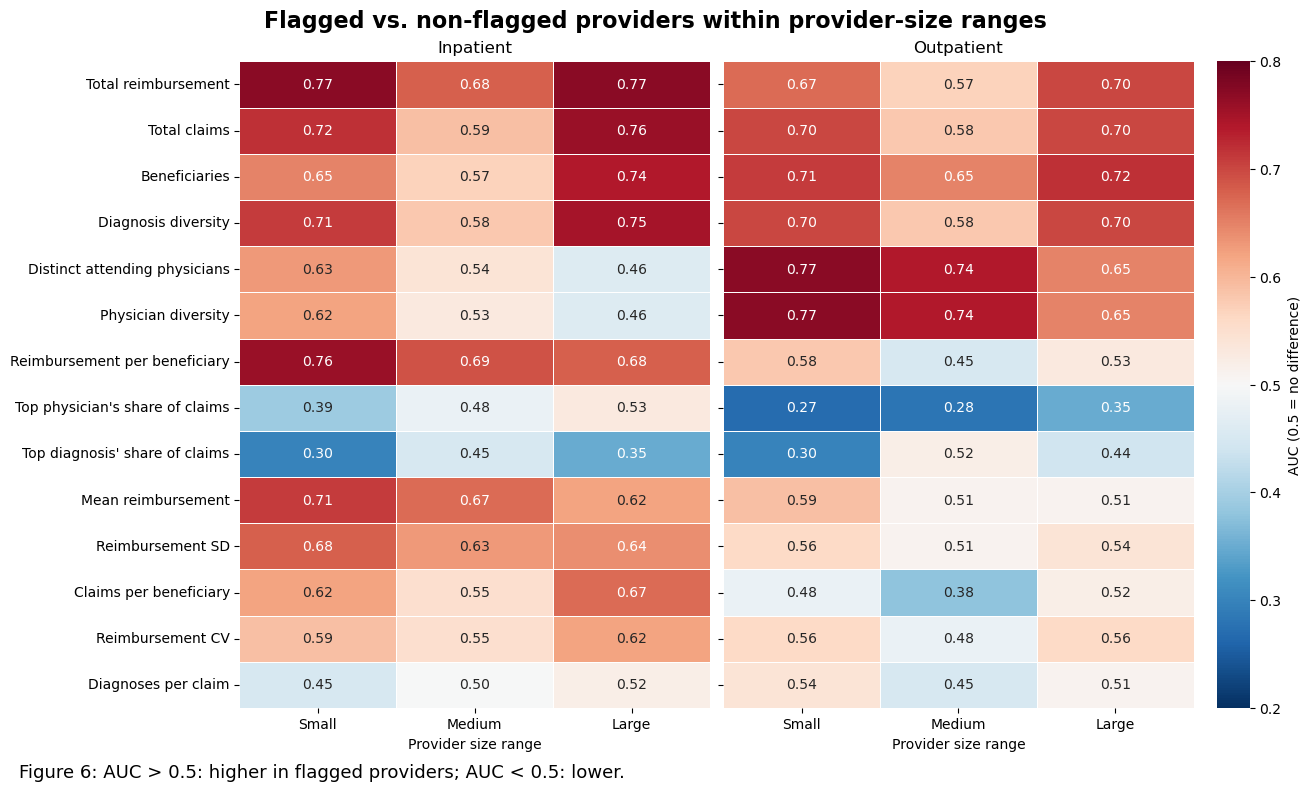

In [18]:
#Split data by claim type
findata_by_type = {Type: g for Type, g in findata_summ.groupby('Type')}

vars_to_test = ["mean_n_dx", 
                'total_claims', 
                'n_bene',
                'reimb_amount_sd', 
                'reimb_amount_mean', 
                'reimb_amount_tot',
                'n_attending', 
                'top_attphy_share', 
                'top_dx_share', 
                'attphy_entropy',
                'dx_entropy', 
                'cv_reimb_amount', 
                'reimb_per_bene', 
                'n_claims_per_bene']
auc_res_l=[]
for claim_t, d in findata_by_type.items():
    auc_res=ut .stratified_auc(findata_by_type[claim_t],
                              vars_to_test,
                              size_col="total_claims",
                              n_bins=3,
                              min_per_class=10)
    auc_res=(auc_res
        .assign(Type=claim_t)
        .pivot(index="feature", columns=("size_bin",'Type'), values="auc")
        .round(2))
    auc_res_l.append(auc_res)

size_names = {0: "Small", 1: "Medium", 2: "Large"}

#heatmap
order = (pd.concat(auc_res_l, axis=1).sub(0.5).abs()
           .mean(axis=1).sort_values(ascending=False).index)

fig, axes = plt.subplots(1, len(auc_res_l), figsize=(6.5 * len(auc_res_l), 7.5),
                         sharey=True, layout="constrained")
axes = np.atleast_1d(axes)

for ax, auc in zip(axes, auc_res_l):
    claim_t = auc.columns[0][1]
    d = auc.reindex(order)
    d.columns = [size_names.get(c[0], c[0]) for c in d.columns]
    d.index = [lbl.get(f, f) for f in d.index]
    sns.heatmap(d, annot=True, fmt=".2f", cmap="RdBu_r", center=0.5, vmin=0.2, vmax=0.8,
                linewidths=0.5, cbar=(ax is axes[-1]),
                cbar_kws={"label": "AUC (0.5 = no difference)"}, ax=ax)
    ax.set_title(claim_t)
    ax.set_xlabel("Provider size range")
    ax.set_ylabel("")

fig.suptitle("Flagged vs. non-flagged providers within provider-size ranges", weight="bold", size=16)
fig.text(0.01, -0.03,
         "Figure 6: AUC > 0.5: higher in flagged providers; AUC < 0.5: lower. ",
         fontsize=13, ha="left")
plt.show()

#### Results 

In inpatient care, the most consistent signal is higher spending per beneficiary (`reimb_per_bene`, AUC≈0.68-0.77), with slightly more claims per beneficiary(`n_claims_per_bene`, AUC≈0.55-0.67). In outpatient care, amounts do not separate the groups; the signal is that flagged providers bill through more attending physicians (`n_attending`, AUC≈0.65-0.77), with less dependence on a single one, and more diverse diagnoses (`dx_entropy`, AUC≈0.58-0.7). Neither group supports a "concentrated billing" pattern: flagged providers look more diversified, not less. Diagnoses per claim show no difference(`mean_n_dx`, AUC≈0.45–0.52), so there is no evidence that flagged providers treat more complex cases by this measure.

**Size is not fully controlled.** Total claims still has an AUC of 0.58–0.76 within size ranges, so providers in the same range still differ in volume. Features mechanically tied to size (total reimbursed, number of beneficiaries, number of physicians, entropy) should be interpreted with caution, and ratio-type features (per beneficiary, per claim, shares, CV) are more informative about behavior.

## 7. Conclusions

1. **Financial patterns.** Median reimbursed amounts per claim are nearly identical between groups. Differences appear in spending per beneficiary and mean reimbursement among inpatient providers, and not in outpatient.
2. **Operational patterns.** No evidence of longer hospital stays or higher daily costs at the median. Inpatient claims per beneficiary are modestly higher among flagged providers; outpatient shows no difference.
3. **Patient and diagnostic complexity.** Diagnoses per claim do not differ. A few outpatient diagnosis codes are over-represented among flagged providers and are candidates for review; no inpatient code stands out.
4. **Concentration and variety.** Flagged providers bill a more diverse set of diagnoses in both claim types, and flagged outpatient providers rely less on a single attending physician. None of these patterns indicates concentrated billing. Because diversity measures grow with volume, they are suggestive rather than conclusive.

Overall, no single variable cleanly separates flagged from non-flagged providers; the differences are moderate and vary by claim type. Provider size is the strongest and most pervasive difference, and it must be handled carefully in any further analysis.

## 8. Next steps
The next phase will build a supervised model to predict `Provider_flag` using provider-level features. The findings above suggest prioritizing ratio-type features (reimbursement per beneficiary, claims per beneficiary, diagnostic diversity, physician concentration) and treating size variables explicitly. The class imbalance (9.35% flagged) calls for stratified splits at the provider level, class weights or tree-based models, and evaluation with recall and precision–recall metrics, since missed fraud is the costly error.